# Vectorial imaging: lines and spaces with s, p and unpolarized light

In optical lithography a projection lens images a mask with lines and
spaces onto a wafer. The smallest half pitch is
$\mathrm{hp} = k_1\,\lambda/\mathrm{NA}$; today's ArF immersion scanners
($\lambda = 193\,$nm, water with $n = 1.437$, NA 1.35) print lines with
$k_1 \approx 0.28$, i.e. a half pitch of 40 nm. At such a numerical aperture
the interfering diffraction orders travel at angles of up to 70° in the
water, and it matters a lot how they are polarized:

- **TE (s)**: the electric field is perpendicular to the plane of incidence,
  i.e. parallel to the lines. All orders have parallel fields and interfere
  with full contrast.
- **TM (p)**: the field lies in the plane of incidence. Two orders at
  $\pm\theta$ have fields that enclose the angle $2\theta$; they interfere with the
  contrast $|\cos 2\theta|$, which vanishes at 45° and reverses beyond.
- **unpolarized**: the incoherent mean of both.

This notebook uses `pyoptics.vectorial_imaging`: Abbe's method (sum over
mutually incoherent source points), a thin mask, an aplanatic projection
lens that rotates the polarization of every diffraction order
(`propagators.aplanatic_rotation()`, see notebook 15), and the polarization
helpers of `pyoptics.polarization` (TE/TM bases, Stokes vectors of partially
polarized light, intensity in the preferred state IPS).

| Function | What it does |
|---|---|
| `lines_spaces_orders(pitch, linewidth, M, line, space)` | Fourier coefficients of a binary or phase shift L/S mask |
| `source_points(shape, sigma, sigma_in, ...)` | conventional, annular, dipole, quasar sources |
| `image_1d(x, pitch, orders, NA, wl, source, polarization, n, defocus, vectorial)` | aerial image of a 1D periodic mask, exact sum over orders |
| `image_2d(mask, x, y, NA, wl, source, polarization, ...)` | the same for any 2D mask (FFT) |
| `contrast(I)`, `nils(x, I, x_edge, w)`, `two_beam_contrast(theta, pol)` | image metrics |

All lengths are image-side values in nm. Convention:
$\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.vectorial_imaging import (lines_spaces_orders, source_points, image_1d, image_2d,
                                        contrast, nils, two_beam_contrast)
from pyoptics.polarization import TE_TM_basis, IPS
from pyoptics.polarization.mueller import S_unpol, S_LVP, S_LHP
from pyoptics.polarization.jones import J_V, J_H
from pyoptics.propagators import aplanatic_rotation
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 193.0          # ArF
n_w = 1.437         # water at 193 nm
NA = 1.35
POLS = [("y", "TE (y, along the lines)", "C0"), ("x", "TM (x, across the lines)", "C3"),
        ("unpolarized", "unpolarized", "C2")]

## 1. Two-beam interference

The simplest image: two plane waves of equal amplitude at $\pm\theta$ (in the
medium). Their intensity pattern $I \propto 1 + V\cos(2k\sin\theta\,x)$ has the
period $\lambda/(2n\sin\theta)$ and the contrast $V = 1$ (TE),
$|\cos 2\theta|$ (TM) and $\cos^2\theta$ (unpolarized). For two beams that pass
symmetrically through the pupil of an immersion lens, the half pitch is
$\mathrm{hp} = \lambda/(4 n\sin\theta) = \lambda/(4\,\mathrm{NA_{eff}})$, i.e.
$k_1 = \mathrm{NA}/(4\,\mathrm{NA_{eff}})$ when both beams use the full pupil.

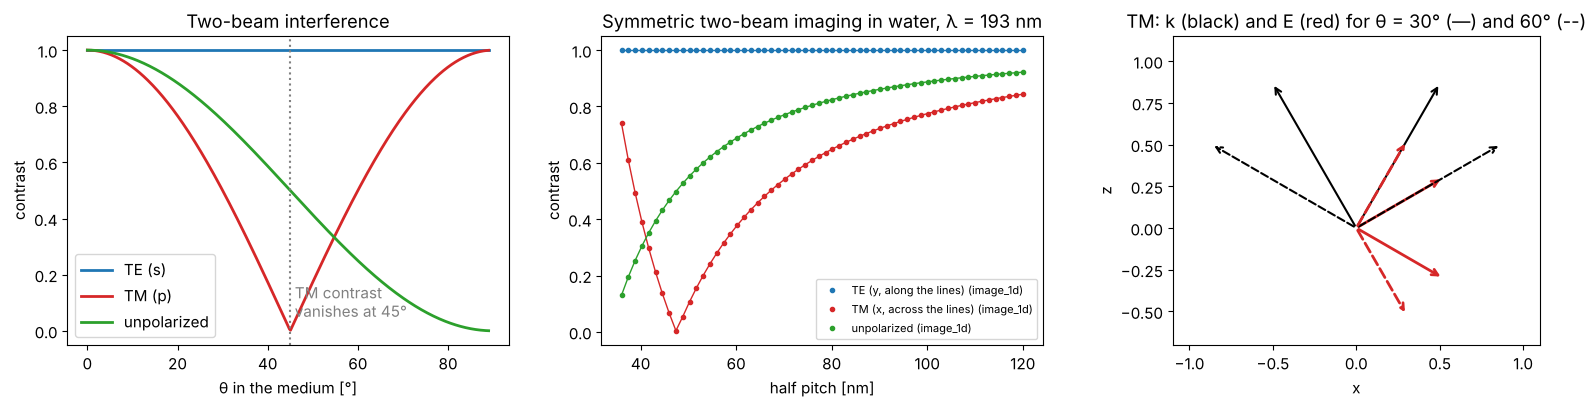

In [2]:
theta = np.radians(np.linspace(0, 89, 400))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for pol, label, c in (("TE", "TE (s)", "C0"), ("TM", "TM (p)", "C3"), ("unpolarized", "unpolarized", "C2")):
    axes[0].plot(np.degrees(theta), two_beam_contrast(theta, pol), color=c, lw=2, label=label)
axes[0].axvline(45, color="gray", ls=":")
axes[0].text(46, 0.05, "TM contrast\nvanishes at 45°", color="gray")
axes[0].set_xlabel("θ in the medium [°]"); axes[0].set_ylabel("contrast"); axes[0].legend()
axes[0].set_title("Two-beam interference")

# the same versus half pitch, numerically with image_1d: orders ±1 of a phase grating
# of pitch p = 4 hp under normal incidence (their interference has the period p/2 = 2 hp):
hp = np.linspace(36, 120, 60)
for pol, label, c in POLS:
    V = []
    for h in hp:
        p = 4*h
        x = np.linspace(-p/2, p/2, 201)
        V.append(contrast(image_1d(x, p, ([-1, 1], [1, 1]), NA, wl, None, pol, n=n_w)))
    axes[1].plot(hp, V, "o", ms=3, color=c, label=label + " (image_1d)")
th_hp = np.arcsin(wl/(4*hp*n_w))
for pol, c in (("TE", "C0"), ("TM", "C3"), ("unpolarized", "C2")):
    axes[1].plot(hp, two_beam_contrast(th_hp, pol), "-", color=c, lw=1)
axes[1].set_xlabel("half pitch [nm]"); axes[1].set_ylabel("contrast")
axes[1].set_title(f"Symmetric two-beam imaging in water, λ = {wl:.0f} nm")
axes[1].legend(fontsize=8)

# field vectors of the two TM waves at 30° and 60°
for t, ls in ((30, "-"), (60, "--")):
    tr = np.radians(t)
    for sgn in (+1, -1):
        k = np.array([sgn*np.sin(tr), np.cos(tr)])
        E = np.array([np.cos(tr), -sgn*np.sin(tr)])
        axes[2].annotate("", xy=k, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k", lw=1.5, ls=ls))
        axes[2].annotate("", xy=0.6*E, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C3", lw=2, ls=ls))
axes[2].set_xlim(-1.1, 1.1); axes[2].set_ylim(-0.7, 1.15); axes[2].set_aspect("equal")
axes[2].set_xlabel("x"); axes[2].set_ylabel("z")
axes[2].set_title("TM: k (black) and E (red) for θ = 30° (—) and 60° (--)")
fig.tight_layout()

## 2. Mask, sources and polarization in the pupil

A binary mask with 40 nm lines and 40 nm spaces (pitch 80 nm) has the
diffraction orders $c_m = -\tfrac12\,\mathrm{sinc}(m/2)$ plus $\tfrac12$ for $m = 0$.
With $\lambda/p = 2.41 > \mathrm{NA}$, normal incidence cannot transmit any
first order. An off-axis source point at $s_x$ shifts the orders by
$\mathrm{NA}\,s_x$ in the pupil; for $s_x = \lambda/(2p\,\mathrm{NA}) = 0.89$ the
orders 0 and $-1$ sit symmetrically at the pupil edge: dipole illumination.

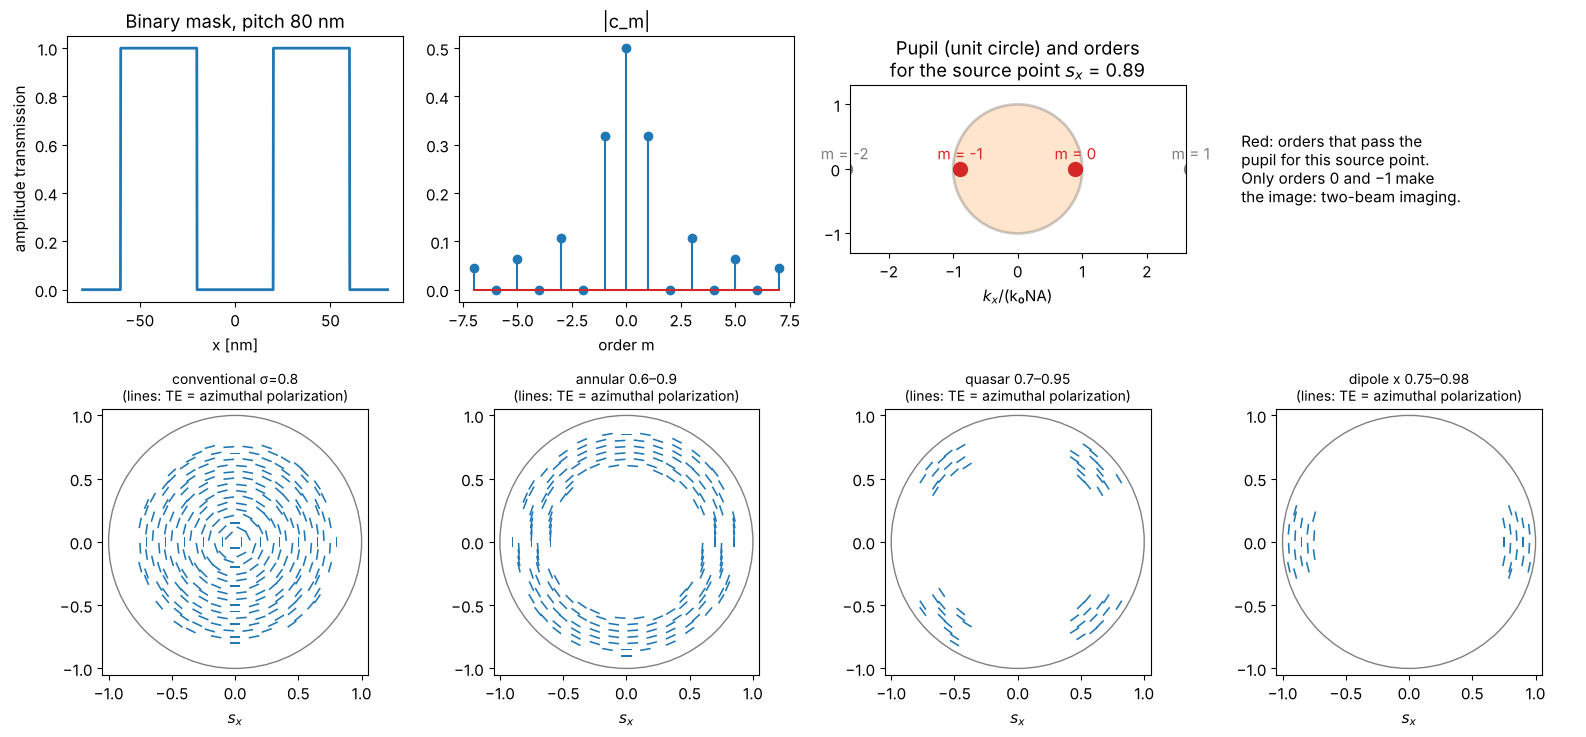

In [3]:
pitch = 80.0
m, c_m = lines_spaces_orders(pitch, pitch/2, 7)
sources = {
    "conventional σ=0.8": source_points("conventional", 0.8, n_samples=41),
    "annular 0.6–0.9": source_points("annular", 0.9, 0.6, n_samples=41),
    "quasar 0.7–0.95": source_points("quasar", 0.95, 0.7, opening_angle=30, n_samples=41),
    "dipole x 0.75–0.98": source_points("dipole", 0.98, 0.75, opening_angle=35, n_samples=41),
}

fig = plt.figure(figsize=(16, 7.5))
ax = fig.add_subplot(2, 4, 1)
xx = np.linspace(-pitch, pitch, 1000)
ax.plot(xx, np.where(np.abs((xx + pitch/2) % pitch - pitch/2) < pitch/4, 0, 1), lw=2)
ax.set_xlabel("x [nm]"); ax.set_title("Binary mask, pitch 80 nm"); ax.set_ylabel("amplitude transmission")
ax = fig.add_subplot(2, 4, 2)
ax.stem(m, np.abs(c_m)); ax.set_xlabel("order m"); ax.set_title("|c_m|")
ax = fig.add_subplot(2, 4, 3)
s_c = wl/(2*pitch*NA)
ax.add_patch(plt.Circle((0, 0), 1, fill=True, fc="C1", alpha=0.2, ec="k", lw=2))
for mm in (-2, -1, 0, 1):
    center = s_c + mm*wl/(pitch*NA)
    passes = abs(center) <= 1
    ax.plot(center, 0, "o", ms=10, color="C3" if passes else "gray")
    ax.text(center, 0.15, f"m = {mm}", ha="center", color="C3" if passes else "gray")
ax.set_xlim(-2.6, 2.6); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
ax.set_title(f"Pupil (unit circle) and orders\nfor the source point $s_x$ = {s_c:.2f}"); ax.set_xlabel("$k_x$/(k₀NA)")
ax = fig.add_subplot(2, 4, 4); ax.axis("off")
ax.text(0, 0.5, "Red: orders that pass the\npupil for this source point.\n"
        "Only orders 0 and −1 make\nthe image: two-beam imaging.", fontsize=11, va="center")
for i, (name, (s_x, s_y, w)) in enumerate(sources.items()):
    ax = fig.add_subplot(2, 4, 5 + i)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, ec="gray"))
    sel = slice(None, None, 3)
    e_TE, _ = TE_TM_basis(s_x, s_y)
    ax.quiver(s_x[sel], s_y[sel], e_TE[0][sel], e_TE[1][sel], pivot="middle", headwidth=1, headlength=0,
              headaxislength=0, width=0.006, scale=25, color="C0")
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05); ax.set_aspect("equal")
    ax.set_title(name + "\n(lines: TE = azimuthal polarization)", fontsize=10)
    ax.set_xlabel("$s_x$")
fig.tight_layout()

## 3. Aerial images at $k_1 = 0.28$: 40 nm lines and spaces

With the $x$ dipole, $y$ polarization is TE for (nearly) all diffraction
orders, $x$ polarization TM. At NA 1.35 the two interfering orders travel at
about $\pm 57°$ in water, beyond 45°: the TM image is *reversed* (bright where
the lines are dark). Added incoherently to the TE image it eats up most of
the contrast of unpolarized light. The scalar model knows nothing of this;
it gives the same image for every polarization.

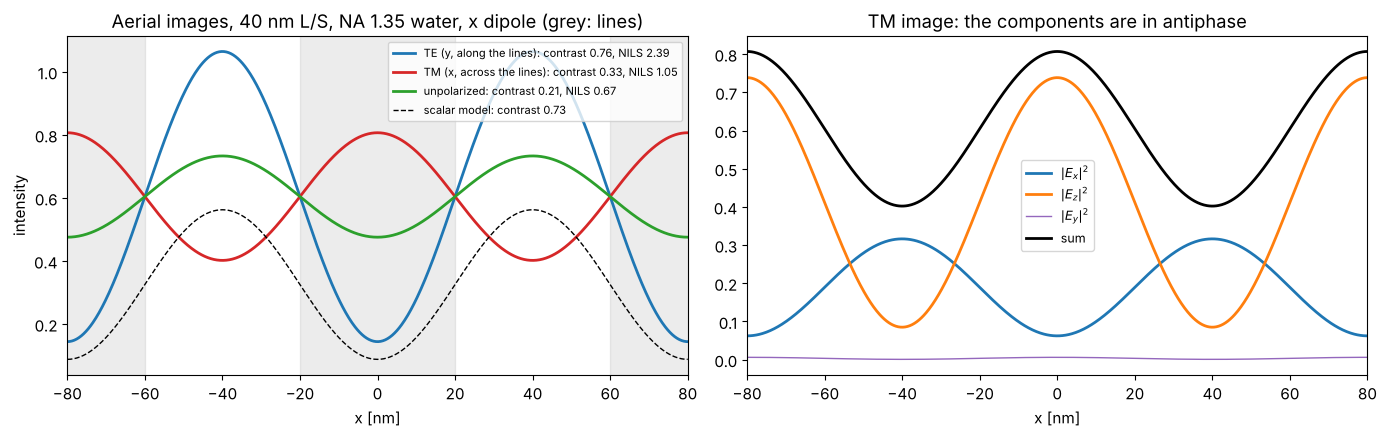

In [4]:
src = sources["dipole x 0.75–0.98"]
x = np.linspace(-pitch, pitch, 801)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for pol, label, c in POLS:
    I = image_1d(x, pitch, (m, c_m), NA, wl, src, pol, n=n_w)
    axes[0].plot(x, I, color=c, lw=2, label=f"{label}: contrast {contrast(I):.2f}, NILS {nils(x, I, pitch/4, pitch/2):.2f}")
I_s = image_1d(x, pitch, (m, c_m), NA, wl, src, "unpolarized", n=n_w, vectorial=False)
axes[0].plot(x, I_s, "k--", lw=1, label=f"scalar model: contrast {contrast(I_s):.2f}")
for xl in np.arange(-pitch, pitch + 1, pitch):
    axes[0].axvspan(xl - pitch/4, xl + pitch/4, color="gray", alpha=0.15)
axes[0].set_xlabel("x [nm]"); axes[0].set_ylabel("intensity"); axes[0].set_xlim(-pitch, pitch)
axes[0].set_title("Aerial images, 40 nm L/S, NA 1.35 water, x dipole (grey: lines)")
axes[0].legend(fontsize=8, loc="upper right")

I_TM, I_xyz = image_1d(x, pitch, (m, c_m), NA, wl, src, "x", n=n_w, return_components=True)
axes[1].plot(x, I_xyz[0], color="C0", lw=2, label="$|E_x|^2$")
axes[1].plot(x, I_xyz[2], color="C1", lw=2, label="$|E_z|^2$")
axes[1].plot(x, I_xyz[1], color="C4", lw=1, label="$|E_y|^2$")
axes[1].plot(x, I_TM, "k", lw=2, label="sum")
axes[1].set_xlabel("x [nm]"); axes[1].set_xlim(-pitch, pitch)
axes[1].set_title("TM image: the components are in antiphase")
axes[1].legend(fontsize=9)
fig.tight_layout()

Each field component on its own is modulated strongly, but $|E_x|^2$ and
$|E_z|^2$ peak at different places; the resist sees their sum.

The absolute intensities of the vectorial and the scalar model differ by the
radiometric (obliquity) factor $1/\sqrt{\cos\theta}$ of the vectorial model:
a reduction lens concentrates the light of the mask side onto oblique
waves in the image space, which raises their amplitude (as for the high NA
focus in notebook 15). `obliquity=False` switches it off.

## 4. Through pitch

Contrast and NILS (normalized image log slope at the nominal line edge,
$w\,|\partial_x \ln I|$, a measure of exposure latitude; resists need about
NILS ≳ 1.5 to 2) against the half pitch, for the dipole adapted to each
pitch ($s_c = \lambda/(2p\,\mathrm{NA})$, poles from $s_c - 0.1$ to $s_c + 0.1$)
and for a fixed annular source.

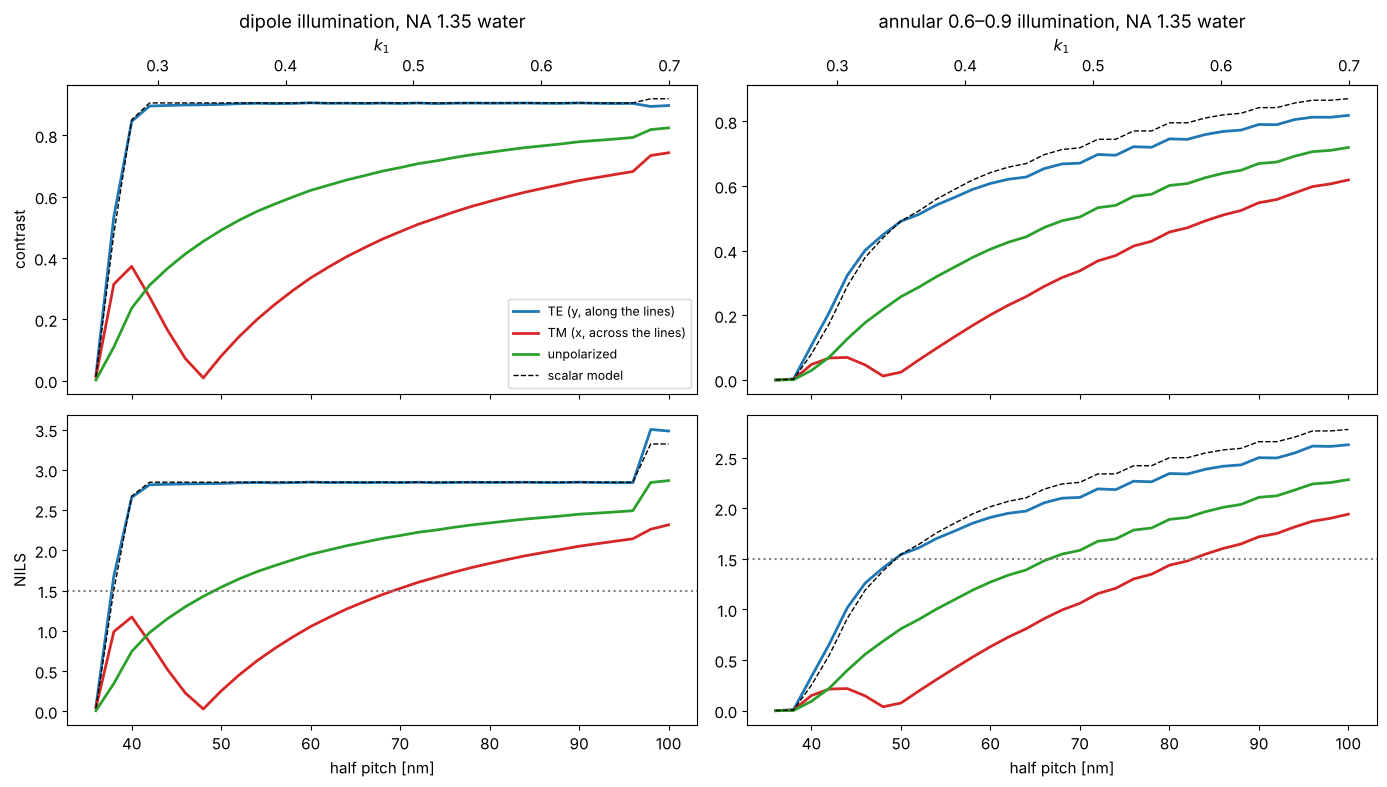

In [5]:
hp_vals = np.arange(36, 101, 2.0)
results = {}
for src_name in ("dipole", "annular 0.6–0.9"):
    for pol, label, c in POLS + [("scalar", "scalar model", "k")]:
        V, N_ = [], []
        for h in hp_vals:
            p = 2*h
            mm, cc = lines_spaces_orders(p, h, 7)
            if src_name == "dipole":
                s_c = min(wl/(2*p*NA), 0.9)
                s = source_points("dipole", s_c + 0.1, s_c - 0.1, opening_angle=35, n_samples=61)
            else:
                s = sources[src_name]
            xs = np.linspace(-p/2, p/2, 401)
            I = image_1d(xs, p, (mm, cc), NA, wl, s, "unpolarized" if pol == "scalar" else pol,
                         n=n_w, vectorial=(pol != "scalar"))
            V.append(contrast(I)); N_.append(nils(xs, I, h/2, h))
        results[(src_name, pol)] = (np.array(V), np.array(N_))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for j, src_name in enumerate(("dipole", "annular 0.6–0.9")):
    for pol, label, c in POLS + [("scalar", "scalar model", "k")]:
        V, N_ = results[(src_name, pol)]
        ls = "--" if pol == "scalar" else "-"
        axes[0, j].plot(hp_vals, V, ls, color=c, lw=2 if pol != "scalar" else 1, label=label)
        axes[1, j].plot(hp_vals, N_, ls, color=c, lw=2 if pol != "scalar" else 1, label=label)
    axes[0, j].set_title(f"{src_name} illumination, NA 1.35 water")
    axes[1, j].axhline(1.5, color="gray", ls=":")
    axes[1, j].set_xlabel("half pitch [nm]")
    sec = axes[0, j].secondary_xaxis("top", functions=(lambda h: h*NA/wl, lambda k1: k1*wl/NA))
    sec.set_xlabel("$k_1$")
axes[0, 0].set_ylabel("contrast"); axes[1, 0].set_ylabel("NILS")
axes[0, 0].legend(fontsize=9)
fig.tight_layout()

(The step of the dipole curves near 97 nm half pitch is the onset of
three-beam imaging: the order $+1$ starts to pass through the pupil.)

Towards the resolution limit TE keeps a high contrast while TM collapses and
even reverses; the scalar model overestimates the contrast of unpolarized
light substantially. This is why hyper-NA immersion scanners use polarized
illumination (TE for the dominant line direction, or azimuthal polarization
for annular and quasar sources).

## 5. Why dry lithography got away with unpolarized light

The same $k_1$ at a smaller NA means smaller angles in the image space. We
compare (all at $k_1 = 0.30$, adapted dipole) dry systems with NA 0.75 and
0.93 and immersion systems with NA 1.2 and 1.35. Plotted: the contrast of
TE, TM and unpolarized light against NA (sweeping dry NA from 0.5 to 0.95 and
immersion NA from 0.5 to 1.35).

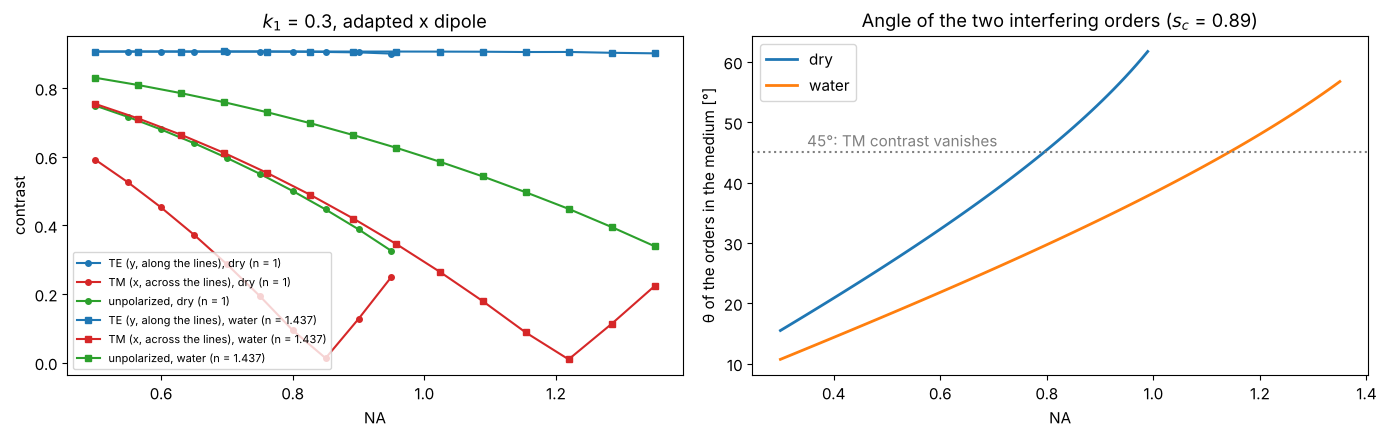

In [6]:
k1 = 0.30
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n_med, name, NA_range, mk in ((1.0, "dry (n = 1)", np.linspace(0.5, 0.95, 10), "o"),
                                  (n_w, "water (n = 1.437)", np.linspace(0.5, 1.35, 14), "s")):
    for pol, label, c in POLS:
        V = []
        for NA_ in NA_range:
            h = k1*wl/NA_; p = 2*h
            mm, cc = lines_spaces_orders(p, h, 7)
            s_c = wl/(2*p*NA_)
            s = source_points("dipole", min(s_c + 0.1, 1), s_c - 0.1, opening_angle=35, n_samples=61)
            xs = np.linspace(-p/2, p/2, 201)
            V.append(contrast(image_1d(xs, p, (mm, cc), NA_, wl, s, pol, n=n_med)))
        axes[0].plot(NA_range, V, mk + "-", color=c, ms=4, label=f"{label}, {name}")
axes[0].set_xlabel("NA"); axes[0].set_ylabel("contrast"); axes[0].set_title(f"$k_1$ = {k1}, adapted x dipole")
axes[0].legend(fontsize=8)
# angle of the interfering orders in the medium
NA_ax = np.linspace(0.3, 1.35, 100)
for n_med, name in ((1.0, "dry"), (n_w, "water")):
    sel = NA_ax <= n_med*0.999
    axes[1].plot(NA_ax[sel], np.degrees(np.arcsin(0.89*NA_ax[sel]/n_med)), lw=2, label=name)
axes[1].axhline(45, color="gray", ls=":"); axes[1].text(0.35, 46, "45°: TM contrast vanishes", color="gray")
axes[1].set_xlabel("NA"); axes[1].set_ylabel("θ of the orders in the medium [°]")
axes[1].set_title("Angle of the two interfering orders ($s_c$ = 0.89)")
axes[1].legend()
fig.tight_layout()

At the same NA, a higher refractive index of the image space makes the
angles smaller ($\sin\theta = \mathrm{NA}\,s/n$); a dry system cannot exceed
NA ≈ 0.93, where the orders still travel at about 56°. In water at NA 1.35
the angles are again as large, now in water, which is why the polarization
problem came back with immersion. (Inside the resist, $n \approx 1.7$, the
angles are smaller again; a full resist model also needs the different
Fresnel transmission of TE and TM at the water-resist interface, see
`thin_films`, which this notebook leaves out.)

## 6. Defocus

Contrast through focus for 45 nm L/S with the adapted dipole: TE keeps its
advantage over the whole focus range.

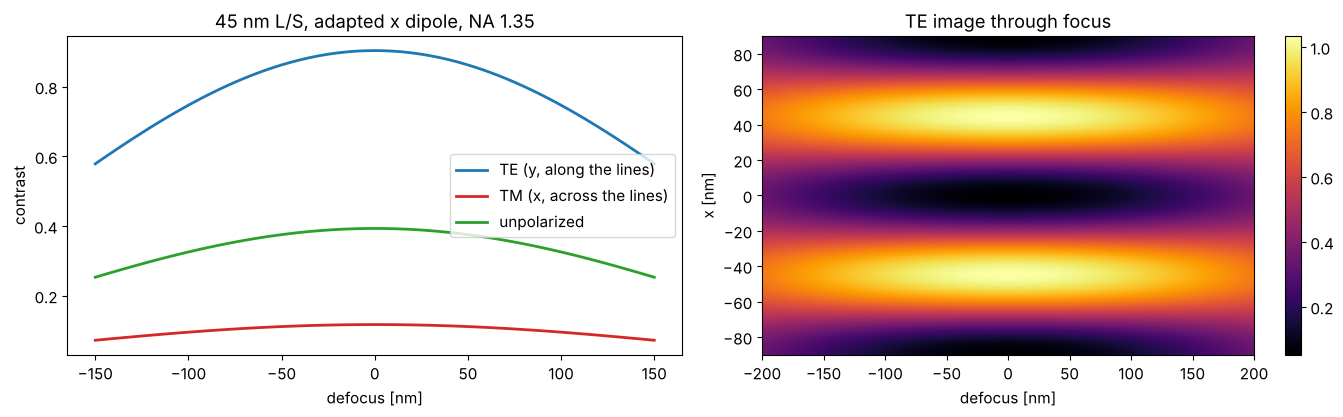

In [7]:
h = 45.0; p = 2*h
mm, cc = lines_spaces_orders(p, h, 7)
s_c = wl/(2*p*NA)
s = source_points("dipole", s_c + 0.1, s_c - 0.1, opening_angle=35, n_samples=61)
dz = np.linspace(-150, 150, 61)
xs = np.linspace(-p/2, p/2, 201)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for pol, label, c in POLS:
    V = [contrast(image_1d(xs, p, (mm, cc), NA, wl, s, pol, n=n_w, defocus=z)) for z in dz]
    axes[0].plot(dz, V, color=c, lw=2, label=label)
axes[0].set_xlabel("defocus [nm]"); axes[0].set_ylabel("contrast"); axes[0].legend()
axes[0].set_title("45 nm L/S, adapted x dipole, NA 1.35")
# x-z image of the TE case
zz = np.linspace(-200, 200, 81)
xz = np.array([image_1d(np.linspace(-p, p, 161), p, (mm, cc), NA, wl, s, "y", n=n_w, defocus=z) for z in zz])
im = axes[1].imshow(xz.T, extent=[zz[0], zz[-1], -p, p], aspect="auto", cmap="inferno")
axes[1].set_xlabel("defocus [nm]"); axes[1].set_ylabel("x [nm]"); axes[1].set_title("TE image through focus")
fig.colorbar(im, ax=axes[1])
fig.tight_layout()

With a symmetric dipole whose poles sit exactly at $s_c$, the two orders pass
the pupil symmetrically and their defocus phases are equal, so the image
would not depend on focus at all; the finite width of the poles causes the
loss of contrast seen here.

## 7. How well polarized must the illumination be?

Real illuminators deliver partially polarized light. The quality is measured
as the intensity in the preferred state, IPS: the fraction of light an
ideal analyzer for the desired (here: $y$, TE) polarization would pass. A
Stokes vector $S = (1, -P, 0, 0)$ (degree of polarization $P$, preferred
state vertical) has $\mathrm{IPS} = (1 + P)/2$; `image_1d()` takes the
Stokes vector directly and splits it into two incoherent Jones vectors
(`polarization.jones_from_stokes()`).

IPS = 0.9: NILS = 2.28 (TE: 2.66, unpolarized: 0.74)
IPS = 0.95: NILS = 2.47 (TE: 2.66, unpolarized: 0.74)


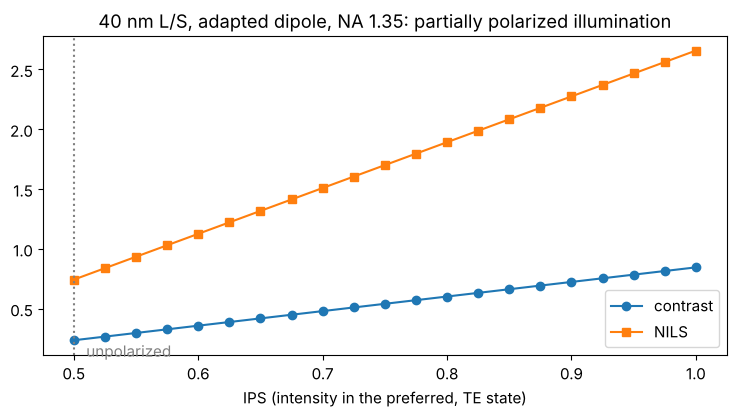

In [8]:
h = 40.0; p = 2*h
mm, cc = lines_spaces_orders(p, h, 7)
s_c = wl/(2*p*NA)
s = source_points("dipole", s_c + 0.1, s_c - 0.1, opening_angle=35, n_samples=61)
xs = np.linspace(-p/2, p/2, 401)
P_vals = np.linspace(0, 1, 21)
ips, V, Nl = [], [], []
for P in P_vals:
    S = np.array([1.0, -P, 0.0, 0.0])
    ips.append(IPS(S, J_V))
    I = image_1d(xs, p, (mm, cc), NA, wl, s, S, n=n_w)
    V.append(contrast(I)); Nl.append(nils(xs, I, h/2, h))
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(ips, V, "o-", label="contrast")
ax.plot(ips, Nl, "s-", label="NILS")
ax.set_xlabel("IPS (intensity in the preferred, TE state)")
ax.set_title("40 nm L/S, adapted dipole, NA 1.35: partially polarized illumination")
ax.axvline(0.5, color="gray", ls=":"); ax.text(0.51, 0.1, "unpolarized", color="gray")
ax.legend(); fig.tight_layout()
for target in (0.9, 0.95):
    print(f"IPS = {target}: NILS = {np.interp(target, ips, Nl):.2f} "
          f"(TE: {Nl[-1]:.2f}, unpolarized: {Nl[0]:.2f})")

Contrast and NILS fall linearly with the TM content, because the TM image is
reversed: every percent of TM light subtracts from the TE image.

## 8. Attenuated phase shift mask

An attenuated PSM transmits 6 % of the intensity through the "dark" lines,
with a phase shift of π: `line = -sqrt(0.06)`. With the dipole it gives a
higher NILS than the binary mask at the same polarization.

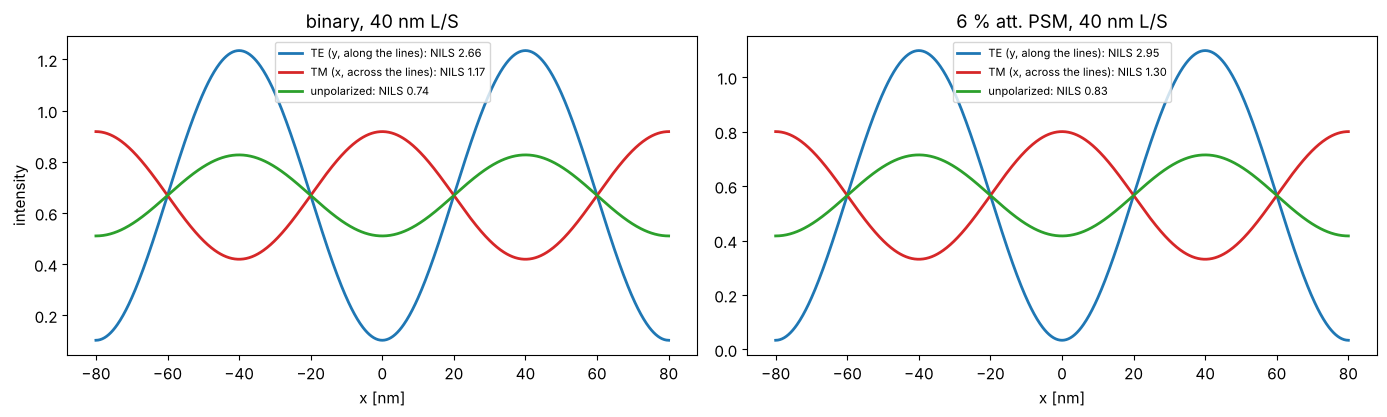

In [9]:
h = 40.0; p = 2*h
s_c = wl/(2*p*NA)
s = source_points("dipole", s_c + 0.1, s_c - 0.1, opening_angle=35, n_samples=61)
xs = np.linspace(-p, p, 801)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, (mask_name, line) in zip(axes, (("binary", 0.0), ("6 % att. PSM", -np.sqrt(0.06)))):
    mm, cc = lines_spaces_orders(p, h, 7, line=line)
    for pol, label, c in POLS:
        I = image_1d(xs, p, (mm, cc), NA, wl, s, pol, n=n_w)
        ax.plot(xs, I, color=c, lw=2, label=f"{label}: NILS {nils(xs, I, h/2, h):.2f}")
    ax.set_title(f"{mask_name}, 40 nm L/S"); ax.set_xlabel("x [nm]"); ax.legend(fontsize=8)
axes[0].set_ylabel("intensity")
fig.tight_layout()

## 9. Two-dimensional masks: contact holes

`image_2d()` treats any mask that is periodic in the computational window.
First a consistency check: lines and spaces in a 2D window give exactly the
image of `image_1d()`. Then an array of 50 nm contact holes at 110 nm pitch
(dark field mask: holes transmit), illuminated by a quasar or annular source with
azimuthal (TE), radial (TM) and no polarization. For holes, both directions
matter; azimuthal polarization is TE for the orders that the poles diffract.

max |image_2d - image_1d| / max: 1.1141640691095005e-15


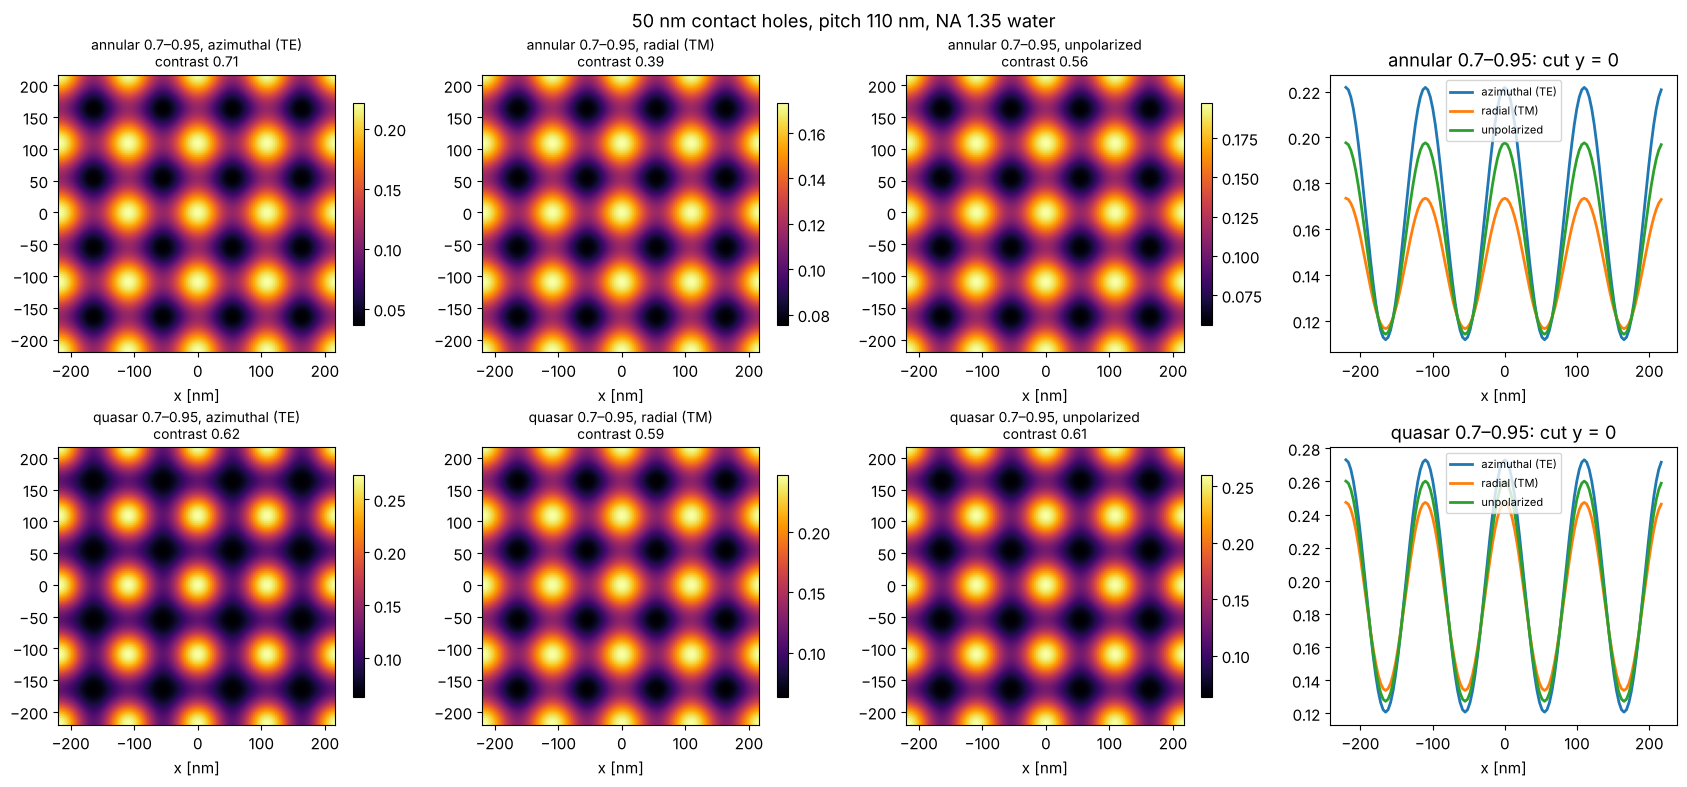

In [10]:
p = 90.0; h = 45.0
N = 96
x2 = grid1d(-2*p, 2*p, N)
y2 = grid1d(-p/2, p/2, 24)
X2, Y2 = np.meshgrid(x2, y2)
mm, cc = lines_spaces_orders(p, h, 4)
mask_ls = sum(c*np.exp(2j*np.pi*k*X2/p) for k, c in zip(mm, cc))
s = source_points("dipole", 0.98, 0.65, opening_angle=35, n_samples=31)
I2 = image_2d(mask_ls, x2, y2, NA, wl, s, "unpolarized", n=n_w)
I1 = image_1d(x2, p, (mm, cc), NA, wl, s, "unpolarized", n=n_w)
print("max |image_2d - image_1d| / max:", np.abs(I2 - I1[None, :]).max()/I1.max())

pc, d = 110.0, 50.0
N = 128
xc = grid1d(-2*pc, 2*pc, N)
Xc, Yc = np.meshgrid(xc, xc)
holes = ((np.abs((Xc + pc/2) % pc - pc/2) < d/2) & (np.abs((Yc + pc/2) % pc - pc/2) < d/2)).astype(float)
srcs = {"annular 0.7–0.95": source_points("annular", 0.95, 0.7, n_samples=31),
        "quasar 0.7–0.95": source_points("quasar", 0.95, 0.7, opening_angle=30, n_samples=31)}
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for i, (sname, s) in enumerate(srcs.items()):
    cuts = {}
    for j, (pol, label) in enumerate((("TE", "azimuthal (TE)"), ("TM", "radial (TM)"), ("unpolarized", "unpolarized"))):
        I = image_2d(holes, xc, xc, NA, wl, s, pol, n=n_w)
        cuts[label] = I[N//2]
        im = axes[i, j].imshow(I, extent=[xc[0], xc[-1], xc[0], xc[-1]], cmap="inferno")
        axes[i, j].set_title(f"{sname}, {label}\ncontrast {contrast(I):.2f}", fontsize=10)
        axes[i, j].set_xlabel("x [nm]")
        fig.colorbar(im, ax=axes[i, j], shrink=0.8)
    for label, cut in cuts.items():
        axes[i, 3].plot(xc, cut, lw=2, label=label)
    axes[i, 3].set_title(f"{sname}: cut y = 0"); axes[i, 3].set_xlabel("x [nm]"); axes[i, 3].legend(fontsize=8)
fig.suptitle("50 nm contact holes, pitch 110 nm, NA 1.35 water")
fig.tight_layout()

## Summary

- At hyper-NA the polarization decides whether lines and spaces near
  $k_1 = 0.28$ can be printed: TE keeps the contrast, TM loses it (and
  reverses beyond 45° in the medium), unpolarized light ends up in between,
  much lower than the scalar model predicts.
- The effect comes from the angle in the image space medium; it was
  negligible for dry NA ≲ 0.7 and returns with immersion.
- Partially polarized illumination is described by a Stokes vector; NILS
  falls linearly with the TM content, so IPS values above 90 % matter.
- `vectorial_imaging.image_1d()` sums the diffraction orders of periodic
  1D masks exactly, `image_2d()` handles any periodic 2D mask; both agree.